# Weather Trend Forecasting
## Notebook 05: Anomaly detection and outlier analysis

Notebook 01 removed values that are physically impossible. This notebook looks for values that are possible but
unusual: a day much warmer or colder than normal for that place and season, or an unusual combination of weather.

Two methods are compared:
1. **MAD z-score** (a z-score built on the median) on the deseasonalized temperature (one variable, easy to explain)
2. **Isolation Forest** on several weather variables at once (multivariate, finds unusual combinations)

Then: where and when the anomalies happen, whether they cluster on single dates (a sign of data errors),
and an outlier analysis of air quality.

This is a look back at the data, not a forecast, so using values on both sides of a day (a centred window) is fine
here. Nothing from this notebook is fed into the forecasting models.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FIG = Path('../reports/figures')
PROC = Path('../data/processed')
METRICS = Path('../reports/metrics')
METRICS.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold',
})
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GREY = '#8a8984'
CITIES = ['Moscow', 'London', 'New Delhi', 'Singapore', 'Canberra', 'Buenos Aires']

def save(fig, name):
    fig.savefig(FIG / name)
    print('saved', FIG / name)

from sklearn.ensemble import IsolationForest

In [2]:
df = pd.read_csv(PROC / 'weather_clean.csv', parse_dates=['date'])
df = df.sort_values(['country', 'location_name', 'date']).reset_index(drop=True)
df['loc'] = df['location_name'] + ', ' + df['country']
print(df.shape, '| locations:', df['loc'].nunique())

(161377, 39) | locations: 185


## 1. Deseasonalizing the temperature

The "normal" temperature for each location and day is the **median of the surrounding 31 days** (15 before, 15 after)
at that location. A median ignores single extreme days, so an anomaly does not hide itself by pulling the normal
towards it. It also follows the seasons and the slow drift of the snapshot hour (notebook 01).

The **residual** is the reading minus that normal.

In [3]:
def centred_median(s):
    return s.rolling(31, center=True, min_periods=15).median()

g = df.groupby('loc')
df['temp_normal'] = g['temperature_celsius'].transform(centred_median)
df['temp_resid'] = df['temperature_celsius'] - df['temp_normal']
df['pressure_resid'] = df['pressure_mb'] - g['pressure_mb'].transform(centred_median)
df['humidity_resid'] = df['humidity'] - g['humidity'].transform(centred_median)
print('residual summary (C):')
df['temp_resid'].describe().round(2)

residual summary (C):


count    161377.00
mean         -0.08
std           2.46
min         -19.20
25%          -1.10
50%           0.00
75%           1.00
max          16.90
Name: temp_resid, dtype: float64

## 2. Method 1: MAD z-score

For each location, the residuals are scaled with the median and the MAD (median absolute deviation) instead of the
mean and standard deviation, because those two are pulled by the extremes we are looking for.

`MAD z = (residual - median) / (1.4826 * MAD)`

A day is an anomaly when |MAD z| > 3.5, the usual cut-off for this method (Iglewicz and Hoaglin), **and** the
residual is at least 3 C. The factor 1.4826 makes the MAD comparable to a standard deviation for normally distributed data.

Why the 3 C minimum: in very stable tropical places (for example Basseterre or Funafuti) the MAD is tiny, so a 4 C
dip during a rain shower gets an extreme z-score. Without the minimum, up to 10% of days in those places were
flagged. A change of less than 3 C from the local normal is not treated as an anomaly anywhere.

In [4]:
def mad_z(s):
    med = s.median()
    mad = (s - med).abs().median()
    return (s - med) / (1.4826 * mad)

df['temp_z'] = df.groupby('loc')['temp_resid'].transform(mad_z)
df['anomaly_z'] = (df['temp_z'].abs() > 3.5) & (df['temp_resid'].abs() >= 3)
print('anomalies (MAD z-score):', df['anomaly_z'].sum(), f"({df['anomaly_z'].mean() * 100:.2f}% of readings)")
print('warm:', (df['anomaly_z'] & (df['temp_z'] > 0)).sum(), '| cold:', (df['anomaly_z'] & (df['temp_z'] < 0)).sum())

anomalies (MAD z-score): 2357 (1.46% of readings)
warm: 713 | cold: 1644


## 3. Method 2: Isolation Forest

Isolation Forest builds random trees that split the data at random points. Unusual rows get isolated after only a few
splits. It looks at several variables together, so it can flag a combination that is rare even when no single
value is extreme.

Inputs, each standardized **per location** so that a normal day in a hot city and in a cold city look the same:
temperature residual, pressure residual, humidity residual, wind, precipitation (log), cloud and visibility.

Settings: 200 trees, and `contamination = 0.01`, which tells the model to flag the 1% most unusual rows.
This share is a choice, not something learned; it was set to be in the same range as the z-score method so
the two can be compared.

In [5]:
iso_cols = ['temp_resid', 'pressure_resid', 'humidity_resid', 'wind_kph', 'precip_log', 'cloud', 'visibility_km']
df['precip_log'] = np.log1p(df['precip_mm'])
X = df[['loc'] + iso_cols].dropna()
Xs = X.groupby('loc')[iso_cols].transform(lambda s: (s - s.mean()) / s.std(ddof=0)).fillna(0)

iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=0, n_jobs=-1).fit(Xs)
df['iso_score'] = np.nan
df.loc[X.index, 'iso_score'] = -iso.score_samples(Xs)
df['anomaly_iso'] = False
df.loc[X.index, 'anomaly_iso'] = iso.predict(Xs) == -1
print('rows used:', len(X))
print('anomalies (Isolation Forest):', df['anomaly_iso'].sum(), f"({df['anomaly_iso'].mean() * 100:.2f}% of readings)")

rows used: 161377
anomalies (Isolation Forest): 1614 (1.00% of readings)


## 4. How do the two methods compare?

In [6]:
both = df['anomaly_z'] & df['anomaly_iso']
either = df['anomaly_z'] | df['anomaly_iso']
print('flagged by z-score only:        ', (df['anomaly_z'] & ~df['anomaly_iso']).sum())
print('flagged by Isolation Forest only:', (~df['anomaly_z'] & df['anomaly_iso']).sum())
print('flagged by both:                 ', both.sum())
print('overlap (both / either):         ', round(both.sum() / either.sum(), 3))
print()
print('mean absolute standardized value of each input, Isolation Forest-only anomalies vs normal rows:')
iso_only = (~df.loc[X.index, 'anomaly_z']) & df.loc[X.index, 'anomaly_iso']
normal = ~df.loc[X.index, 'anomaly_iso']
pd.DataFrame({'iso only': Xs[iso_only.values].abs().mean(), 'normal rows': Xs[normal.values].abs().mean()}).round(2)

flagged by z-score only:         1884
flagged by Isolation Forest only: 1141
flagged by both:                  473
overlap (both / either):          0.135

mean absolute standardized value of each input, Isolation Forest-only anomalies vs normal rows:


,iso only,normal rows
temp_resid,1.48,0.72
pressure_resid,1.62,0.73
humidity_resid,1.82,0.72
wind_kph,1.52,0.78
precip_log,5.00,0.46
cloud,1.62,0.84
visibility_km,3.04,0.53


saved ../reports/figures/05_method_comparison.png


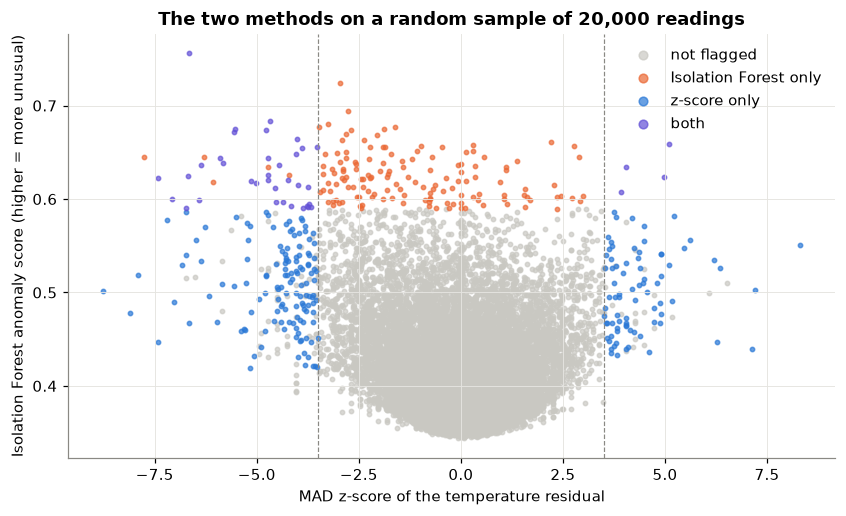

In [7]:
sample = df.dropna(subset=['iso_score']).sample(20000, random_state=0)
fig, ax = plt.subplots(figsize=(9, 5))
for mask, color, label in [(~sample['anomaly_z'] & ~sample['anomaly_iso'], '#c9c8c2', 'not flagged'),
                           (sample['anomaly_iso'] & ~sample['anomaly_z'], PALETTE[1], 'Isolation Forest only'),
                           (sample['anomaly_z'] & ~sample['anomaly_iso'], PALETTE[0], 'z-score only'),
                           (sample['anomaly_z'] & sample['anomaly_iso'], PALETTE[6], 'both')]:
    ax.scatter(sample.loc[mask, 'temp_z'], sample.loc[mask, 'iso_score'], s=8, color=color, alpha=0.7, label=label)
ax.axvline(3.5, color=GREY, linestyle='--', linewidth=0.8)
ax.axvline(-3.5, color=GREY, linestyle='--', linewidth=0.8)
ax.set_xlabel('MAD z-score of the temperature residual')
ax.set_ylabel('Isolation Forest anomaly score (higher = more unusual)')
ax.set_title('The two methods on a random sample of 20,000 readings')
ax.legend(frameon=False, markerscale=2)
save(fig, '05_method_comparison.png')
plt.show()

Grey points beyond the dashed lines have a high z-score but a residual under 3 C, so they are not flagged.
The z-score method only sees temperature, so it flags every large warm or cold spike. Isolation Forest also flags
days where temperature is normal but wind, pressure or rain are unusual (storms, very windy days), and it skips some
temperature spikes that are otherwise ordinary days. The two methods answer different questions and are best used together.

## 5. An example: London

The thin line is the reading, the thick line the 31-day median ("normal"). Points are the flagged days.

saved ../reports/figures/05_anomalies_london.png


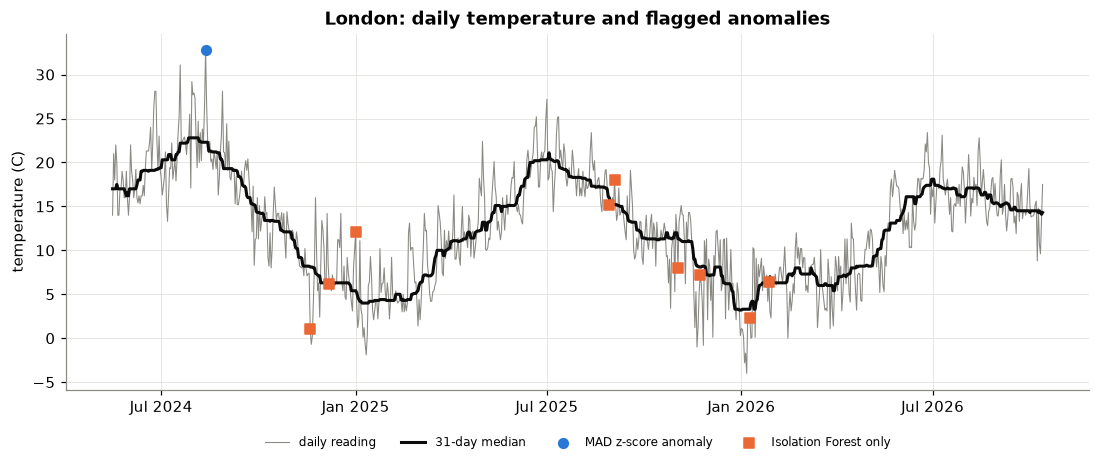

,temperature_celsius,temp_normal,temp_z,condition_text
date,,,,
2024-08-12,32.8,22.3,3.7,Sunny


In [8]:
city = df[df['location_name'] == 'London'].set_index('date')
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(city.index, city['temperature_celsius'], color=GREY, linewidth=0.7, label='daily reading')
ax.plot(city.index, city['temp_normal'], color='#0b0b0b', linewidth=2, label='31-day median')
z = city[city['anomaly_z']]
i = city[city['anomaly_iso'] & ~city['anomaly_z']]
ax.scatter(z.index, z['temperature_celsius'], color=PALETTE[0], s=40, zorder=3, label='MAD z-score anomaly')
ax.scatter(i.index, i['temperature_celsius'], color=PALETTE[1], s=40, marker='s', zorder=3, label='Isolation Forest only')
ax.set_ylabel('temperature (C)')
ax.set_title('London: daily temperature and flagged anomalies')
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(frameon=False, ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.1))
save(fig, '05_anomalies_london.png')
plt.show()
city.loc[city['anomaly_z'], ['temperature_celsius', 'temp_normal', 'temp_z', 'condition_text']].round(1)

## 6. The largest temperature anomalies

In [9]:
top = df.loc[df['temp_z'].abs().sort_values(ascending=False).index[:12],
             ['loc', 'date', 'temperature_celsius', 'temp_normal', 'temp_resid', 'temp_z', 'condition_text']]
top.round({'temperature_celsius': 1, 'temp_normal': 1, 'temp_resid': 1, 'temp_z': 1})

,loc,date,temperature_celsius,temp_normal,temp_resid,temp_z,condition_text
74889,"Tarawa, Kiribati",2026-07-11,24.5,28.4,-3.9,-13.2,Torrential rain shower
40091,"Roseau, Dominica",2024-06-12,35.3,30.1,5.2,11.7,Partly cloudy
116639,"Basseterre, Saint Kitts and Nevis",2026-01-01,20.0,25.1,-5.1,-11.5,Partly cloudy
86498,"Dhidhdhoo, Maldives",2024-11-19,24.6,28.0,-3.4,-11.5,Light drizzle
40081,"Roseau, Dominica",2024-06-02,26.0,31.0,-5.0,-11.2,Light rain
40078,"Roseau, Dominica",2024-05-30,26.0,31.0,-5.0,-11.2,Partly cloudy
128622,"Mogadishu, Somalia",2025-04-16,26.3,31.3,-5.0,-11.2,Light rain
128328,"Mogadishu, Somalia",2024-06-23,24.1,29.1,-5.0,-11.2,Overcast
143899,"Port Of Spain, Trinidad and Tobago",2024-05-16,26.0,31.0,-5.0,-11.2,Partly cloudy
39245,"Djibouti, Djibouti",2024-07-10,47.1,37.2,9.9,11.1,Mist


## 7. Do anomalies cluster on single dates?

Real weather anomalies affect one region at a time. If many locations around the world are flagged on the same day,
it is more likely a data problem (like 17 August 2026, removed in notebook 01).

In [10]:
print('UTC time of the snapshots on the first two days:')
for d in ['2024-05-16', '2024-05-17']:
    print(d, df.loc[df['date'] == d, 'time_utc'].str[11:16].value_counts().head(2).to_dict())

UTC time of the snapshots on the first two days:
2024-05-16 {'08:45': 183}
2024-05-17 {'16:00': 143, '16:15': 38}


days with the highest share of locations flagged (%):
            locations      z  iso
date                             
2024-07-21          1  100.0  0.0
2024-05-16        183   18.6  5.5
2024-09-13        185    8.1  4.3
2025-02-25        184    7.6  5.4
2026-02-02        184    7.6  0.5
2025-04-18        185    7.0  1.6
2025-03-21        185    7.0  3.2
2024-11-28        185    7.0  0.5
saved ../reports/figures/05_anomalies_per_day.png


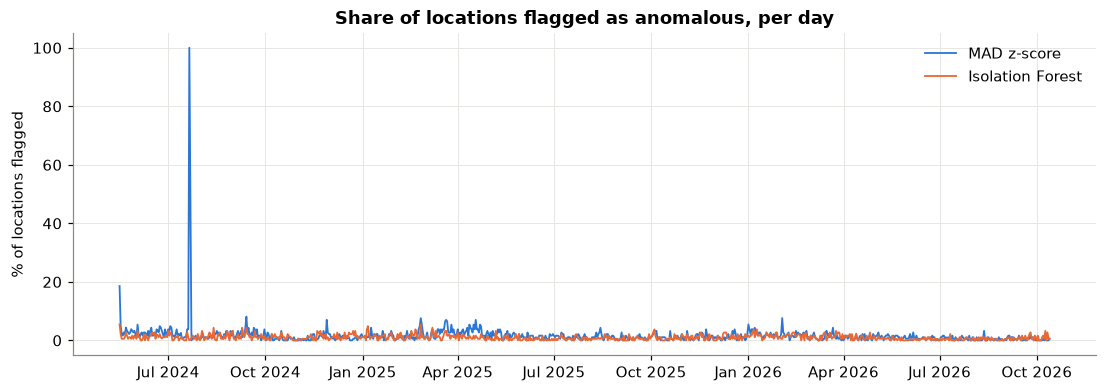

In [11]:
daily = df.groupby('date').agg(locations=('loc', 'size'), z=('anomaly_z', 'mean'), iso=('anomaly_iso', 'mean'))
daily[['z', 'iso']] *= 100
print('days with the highest share of locations flagged (%):')
print(daily.sort_values('z', ascending=False).head(8).round(1))

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily.index, daily['z'], color=PALETTE[0], linewidth=1.2, label='MAD z-score')
ax.plot(daily.index, daily['iso'], color=PALETTE[1], linewidth=1.2, label='Isolation Forest')
ax.set_ylabel('% of locations flagged')
ax.set_title('Share of locations flagged as anomalous, per day')
ax.legend(frameon=False)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
save(fig, '05_anomalies_per_day.png')
plt.show()

## 8. Where and when anomalies happen

saved ../reports/figures/05_anomalies_month_continent.png


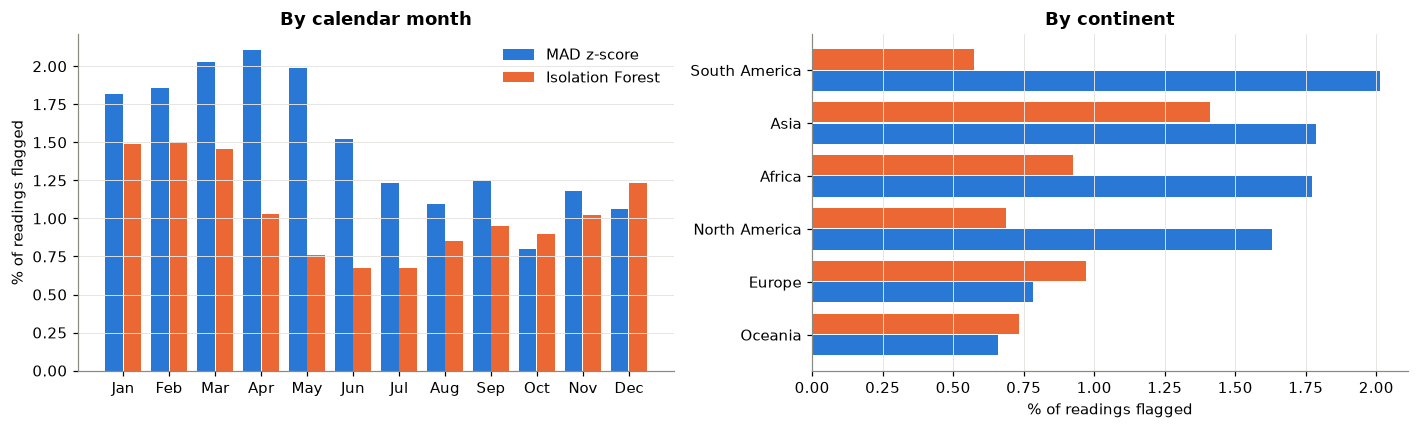

,anomaly_z,anomaly_iso
continent,,
Oceania,0.66,0.73
Europe,0.78,0.97
North America,1.63,0.69
Africa,1.77,0.93
Asia,1.79,1.41
South America,2.01,0.57


In [12]:
by_month = df.groupby(df['date'].dt.month)[['anomaly_z', 'anomaly_iso']].mean() * 100
by_cont = df.groupby('continent')[['anomaly_z', 'anomaly_iso']].mean().sort_values('anomaly_z') * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(12)
axes[0].bar(x - 0.2, by_month['anomaly_z'], width=0.38, color=PALETTE[0], label='MAD z-score')
axes[0].bar(x + 0.2, by_month['anomaly_iso'], width=0.38, color=PALETTE[1], label='Isolation Forest')
axes[0].set_xticks(x, ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
axes[0].set_ylabel('% of readings flagged')
axes[0].set_title('By calendar month')
axes[0].legend(frameon=False)
axes[0].grid(axis='x', visible=False)
y = np.arange(len(by_cont))
axes[1].barh(y - 0.2, by_cont['anomaly_z'], height=0.38, color=PALETTE[0])
axes[1].barh(y + 0.2, by_cont['anomaly_iso'], height=0.38, color=PALETTE[1])
axes[1].set_yticks(y, by_cont.index)
axes[1].set_xlabel('% of readings flagged')
axes[1].set_title('By continent')
axes[1].grid(axis='y', visible=False)
fig.tight_layout()
save(fig, '05_anomalies_month_continent.png')
plt.show()
by_cont.round(2)

saved ../reports/figures/05_anomaly_rate_map.png


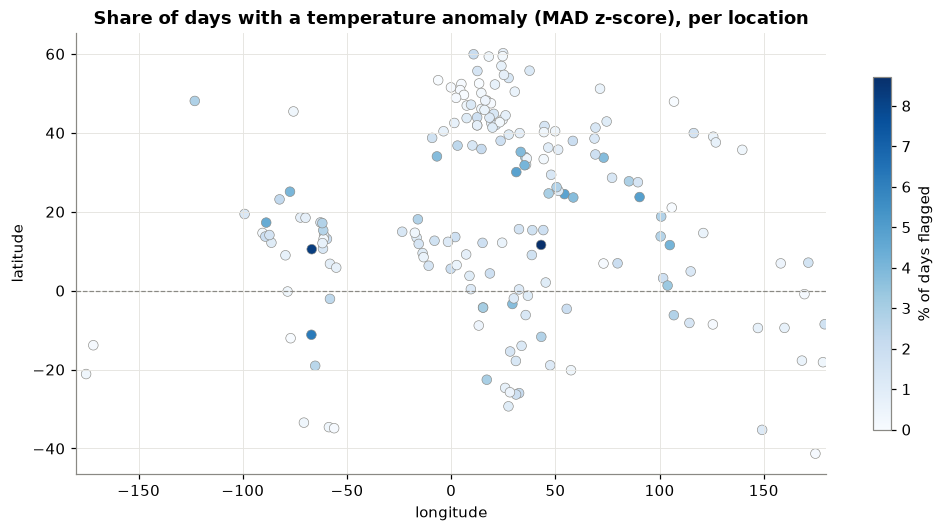

locations with the highest share of anomalous days:
                                   lat     lon  rate  resid_sd
loc                                                           
Djibouti, Djibouti               11.60   43.15  8.71      1.94
Caracas, Venezuela               10.50  -66.92  8.24      2.19
National, Bolivia               -11.18  -67.08  6.21      2.00
Dhaka, Bangladesh                23.72   90.41  4.91      2.09
Cairo, Egypt                     30.05   31.25  4.81      2.50
Abu Dhabi, United Arab Emirates  24.47   54.37  4.79      2.34
Belmopan, Belize                 17.25  -88.77  4.48      1.38
Phnom Penh, Cambodia             11.55  104.92  4.12      2.27

correlation of anomaly share with |latitude|: -0.25


In [13]:
loc_rate = df.groupby('loc').agg(lat=('latitude', 'mean'), lon=('longitude', 'mean'),
                                 rate=('anomaly_z', 'mean'), resid_sd=('temp_resid', 'std'))
loc_rate['rate'] *= 100

fig, ax = plt.subplots(figsize=(11, 5.2))
sc = ax.scatter(loc_rate['lon'], loc_rate['lat'], c=loc_rate['rate'], cmap='Blues', s=40,
                edgecolor='#8a8984', linewidth=0.4, vmin=0)
ax.axhline(0, color=GREY, linewidth=0.8, linestyle='--')
ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
ax.set_xlim(-180, 180)
ax.set_title('Share of days with a temperature anomaly (MAD z-score), per location')
fig.colorbar(sc, ax=ax, label='% of days flagged', shrink=0.8)
save(fig, '05_anomaly_rate_map.png')
plt.show()
print('locations with the highest share of anomalous days:')
print(loc_rate.sort_values('rate', ascending=False).head(8).round(2))
print()
print('correlation of anomaly share with |latitude|:', round(loc_rate['rate'].corr(loc_rate['lat'].abs()), 2))

## 9. Air quality outliers

Air quality values are very skewed: most readings are low and a few are extremely high. On a log scale the
distribution is much closer to symmetric, so outliers are defined there: a PM2.5 reading is an outlier when its log
is more than 1.5 interquartile ranges above the third quartile (the usual box plot rule).

These are not errors. They are pollution episodes (dust storms, smoke, winter smog), so they are kept in the data.

PM2.5 median: 13.3 ug/m3 | 99th percentile: 153.6 | max: 1614.1
outlier cut-off (log box plot rule): 194.8 ug/m3
outlier readings: 881 (0.55%)


saved ../reports/figures/05_pm25_outliers.png


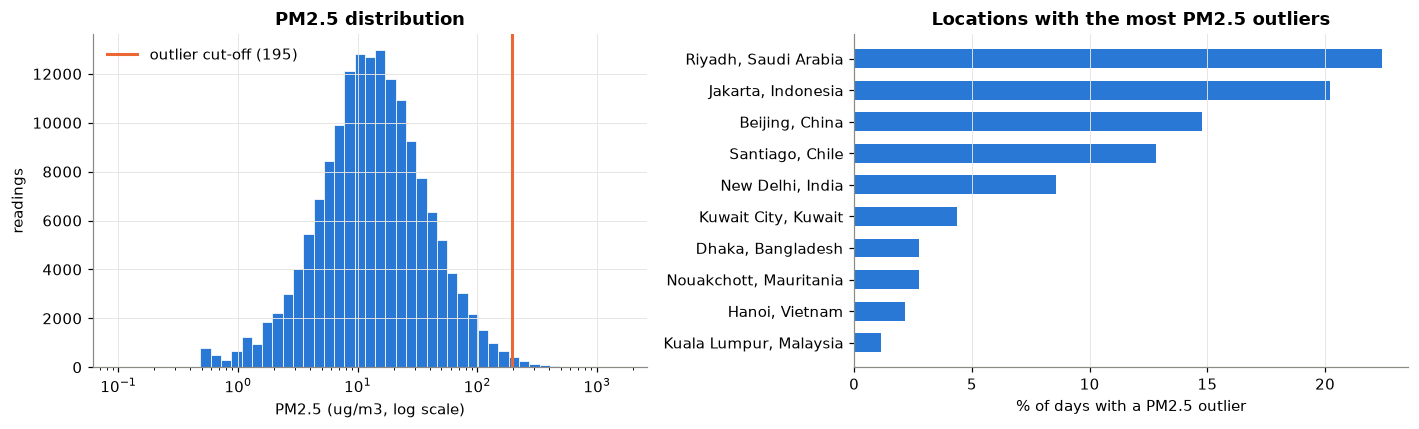

In [14]:
pm = df['air_quality_PM2.5']
logpm = np.log10(pm)
q1, q3 = logpm.quantile([0.25, 0.75])
cut = 10 ** (q3 + 1.5 * (q3 - q1))
df['pm25_outlier'] = pm > cut
print('PM2.5 median:', round(pm.median(), 1), 'ug/m3 | 99th percentile:', round(pm.quantile(0.99), 1), '| max:', round(pm.max(), 1))
print('outlier cut-off (log box plot rule):', round(cut, 1), 'ug/m3')
print('outlier readings:', df['pm25_outlier'].sum(), f"({df['pm25_outlier'].mean() * 100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(pm, bins=np.logspace(np.log10(max(pm.min(), 0.1)), np.log10(pm.max()), 50), color=PALETTE[0], edgecolor='white', linewidth=0.5)
axes[0].axvline(cut, color=PALETTE[1], linewidth=2, label=f'outlier cut-off ({cut:.0f})')
axes[0].set_xscale('log')
axes[0].set_xlabel('PM2.5 (ug/m3, log scale)')
axes[0].set_ylabel('readings')
axes[0].set_title('PM2.5 distribution')
axes[0].legend(frameon=False)

top_pm = df.groupby('loc')['pm25_outlier'].mean().sort_values().tail(10) * 100
axes[1].barh(top_pm.index, top_pm.values, color=PALETTE[0], height=0.6)
axes[1].set_xlabel('% of days with a PM2.5 outlier')
axes[1].set_title('Locations with the most PM2.5 outliers')
axes[1].grid(axis='y', visible=False)
fig.tight_layout()
save(fig, '05_pm25_outliers.png')
plt.show()

In [15]:
print('PM2.5 outlier share by continent (%):')
print((df.groupby('continent')['pm25_outlier'].mean() * 100).sort_values(ascending=False).round(2))
print()
print('PM2.5 outlier share by calendar month, all locations (%):')
print((df.groupby(df['date'].dt.month)['pm25_outlier'].mean() * 100).round(2).to_string())

PM2.5 outlier share by continent (%):
continent
Asia             1.65
South America    1.22
Africa           0.17
Europe           0.03
North America    0.01
Oceania          0.00
Name: pm25_outlier, dtype: float64

PM2.5 outlier share by calendar month, all locations (%):
date
1     0.80
2     0.54
3     0.36
4     0.29
5     0.63
6     0.67
7     0.56
8     0.74
9     0.39
10    0.14
11    0.62
12    0.79


## Summary

- **MAD z-score (temperature only):** 2,357 anomalies, 1.46% of readings. Cold anomalies (1,644) are more than twice
  as common as warm ones (713). Many of the largest cold ones are tropical days with rain in the condition label,
  for example Tarawa on 11 July 2026 (24.5 C against a normal of 28.4 C, "Torrential rain shower").
- **Isolation Forest (seven variables):** 1,614 anomalies (1.00%, as set by the contamination parameter).
- **The methods mostly disagree:** only 473 readings are flagged by both (overlap 13.5%). Isolation Forest-only
  anomalies have very unusual precipitation (5.0 standard deviations from the local mean, against 0.5 for normal
  rows) and visibility (3.0 vs 0.5), so it mainly finds heavy rain and poor visibility days, which the
  temperature-only method cannot see.
- **No new global data error was found.** The day with the most flags is the first day of data (18.6% of
  locations). Its snapshot was taken at 08:45 UTC, while the next days were taken around 16:00 UTC, so the
  temperatures were measured at a different time of day. That is the snapshot timing issue again, not weather.
  Every other day stays at or below 8.1%.
- **Where:** the highest shares of anomalous days are in Djibouti (8.7%) and Caracas (8.2%). By continent the
  z-score rate ranges from 0.66% (Oceania) to 2.01% (South America).
- **Air quality:** PM2.5 has a median of 13.3 ug/m3, a 99th percentile of 153.6 and a maximum of 1,614.1. With a
  box plot rule on the log scale, readings above 194.8 ug/m3 are outliers: 881 readings (0.55%). They are
  concentrated in a few cities: Riyadh (22.4% of days), Jakarta (20.2%), Beijing (14.8%), Santiago (12.8%) and
  New Delhi (8.6%). They are pollution episodes, not errors, so they stay in the data.